In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [59]:
df = pd.read_csv('concrete_data.csv')

In [60]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [61]:
df.isna().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [62]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [63]:
from sklearn.model_selection import train_test_split, cross_val_score

In [64]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:, :-1], df.iloc[:, -1], test_size= 0.25, random_state= 42)

In [65]:
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LinearRegression
import scipy.stats as sts

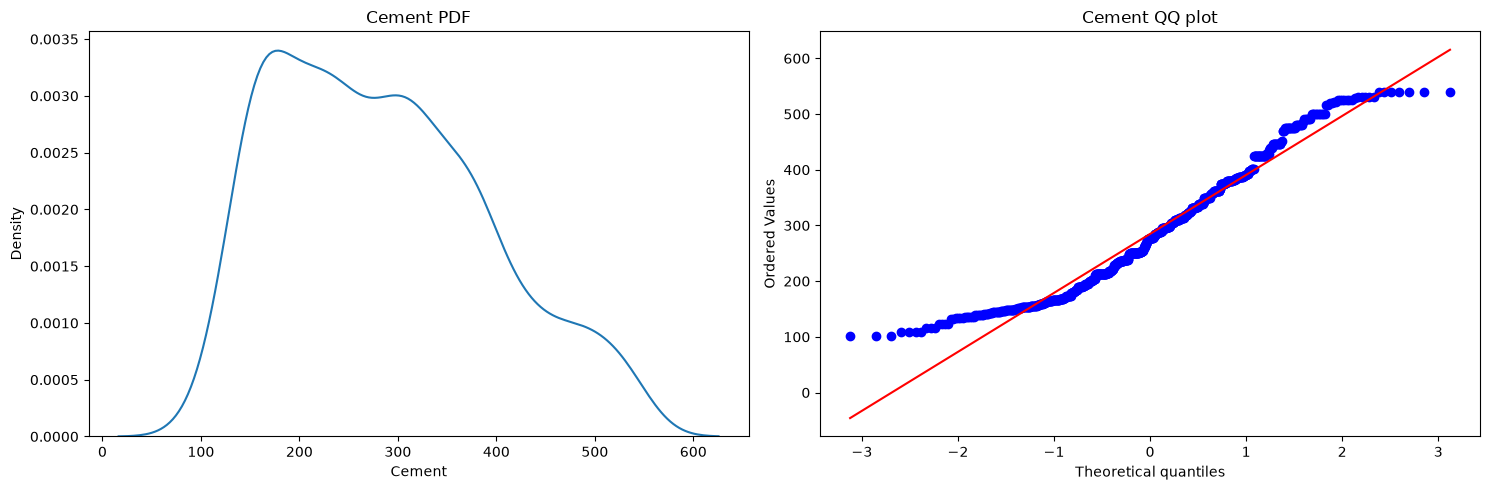

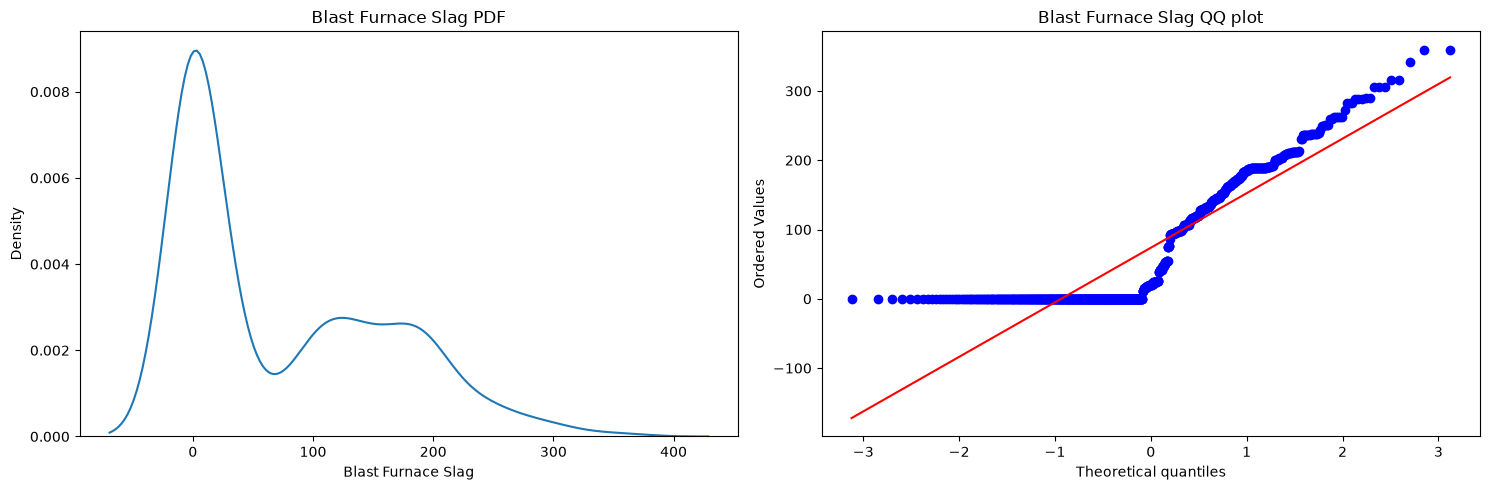

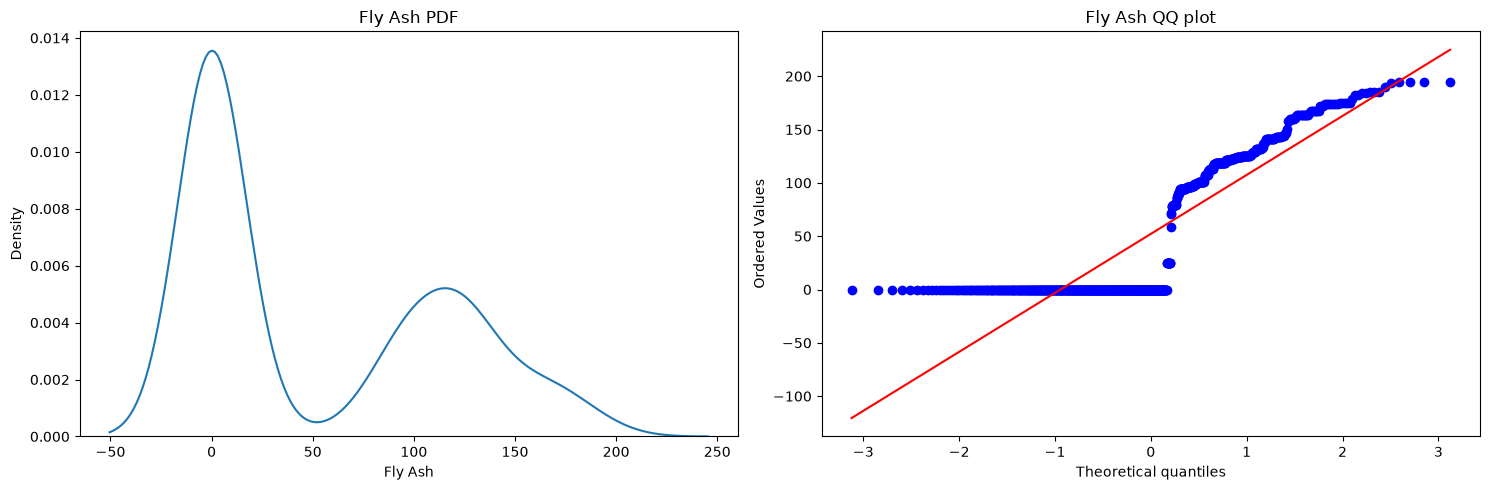

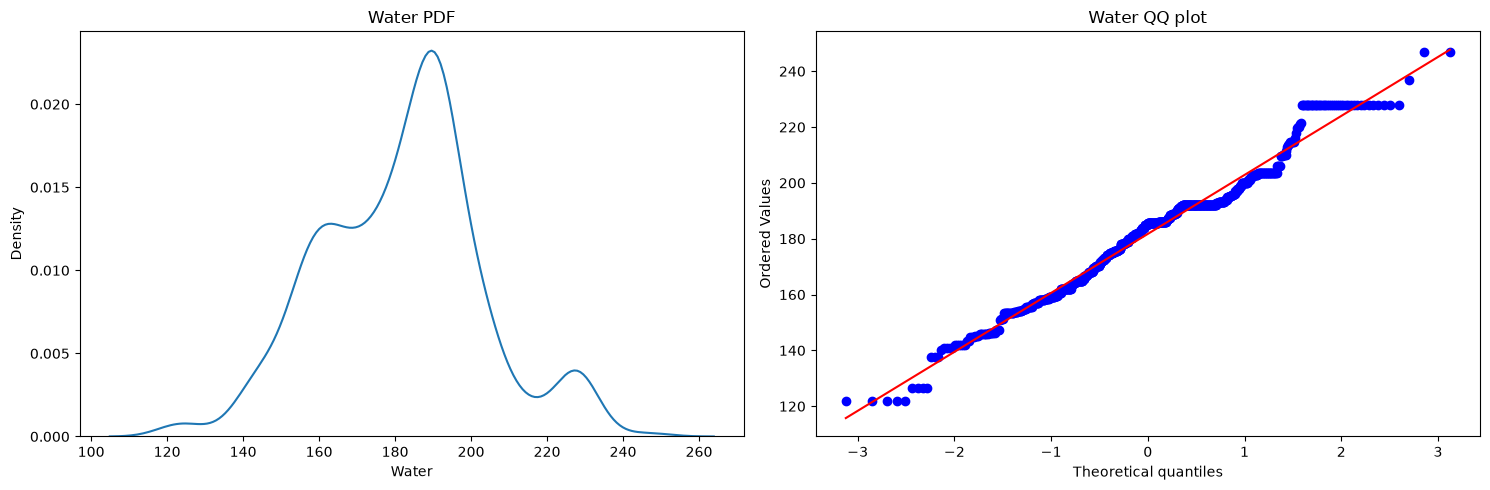

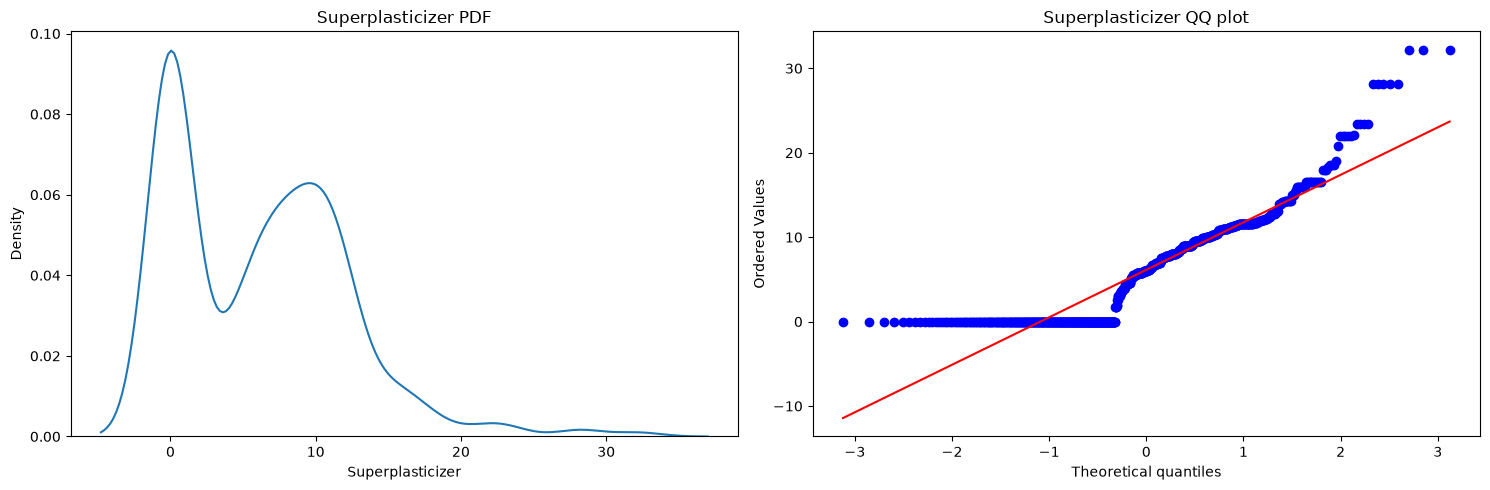

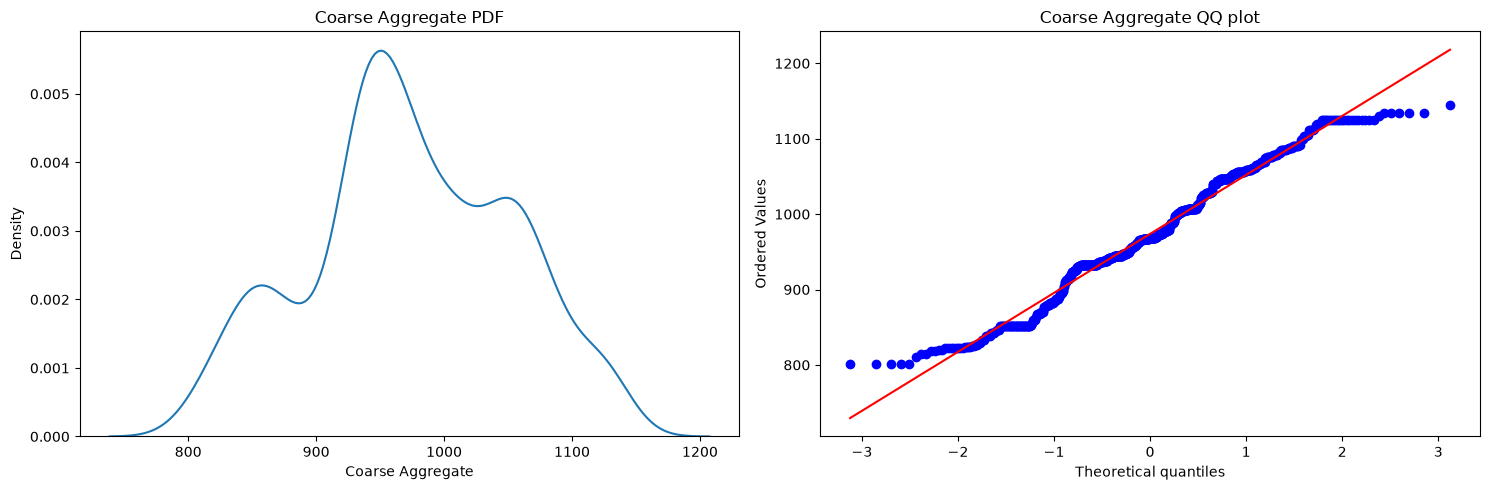

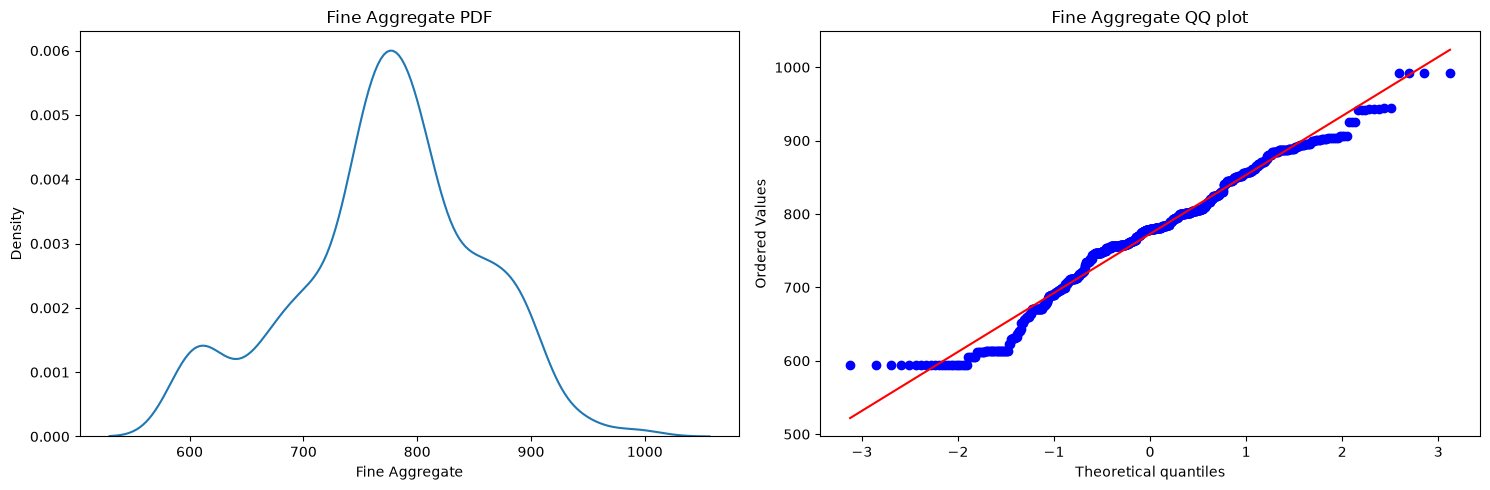

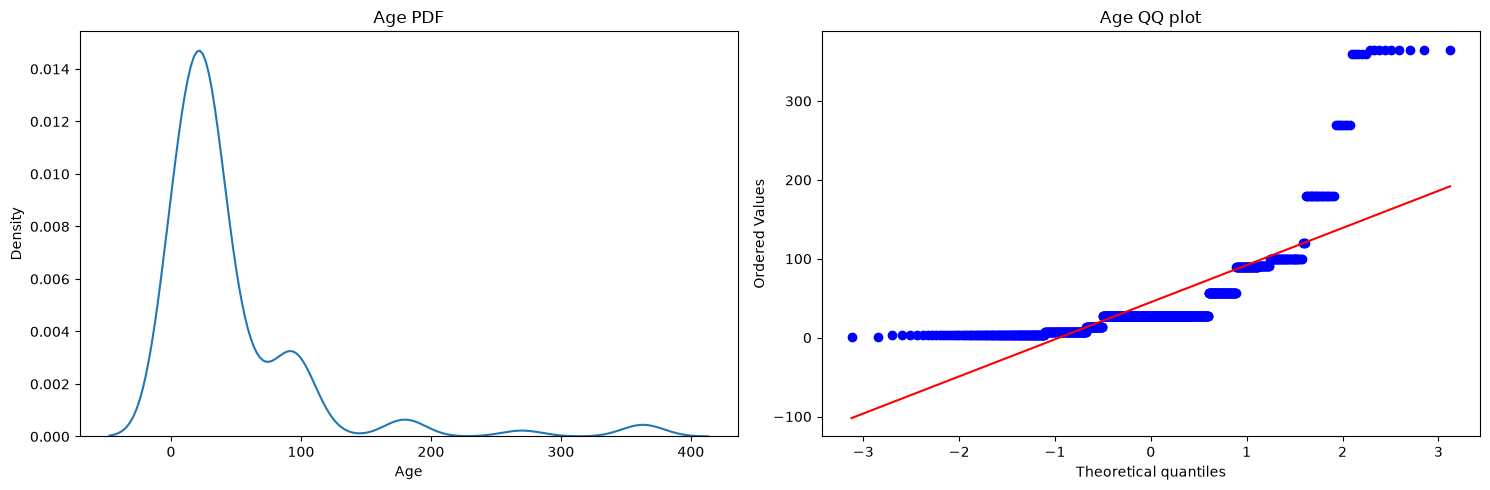

In [66]:
for column in X_train.columns:

    fig, ax = plt.subplots(1, 2, figsize = (15, 5))
    sns.kdeplot(X_train[column], ax= ax[0])
    ax[0].set_title(f'{column} PDF')

    sts.probplot(X_train[column], plot= ax[1])
    ax[1].set_title(f'{column} QQ plot')

    plt.tight_layout()

In [67]:
lr = LinearRegression()

cross_val_score(lr, X_train, y_train, scoring= 'r2', cv= 5).mean()

np.float64(0.5913147611965391)

In [68]:
from sklearn.preprocessing import PowerTransformer

In [69]:
pt = PowerTransformer('box-cox')

In [70]:
X_train_trans = pt.fit_transform(X_train + 0.00001)
X_test_trans = pt.transform(X_test + 0.00001)

In [91]:
df2 = pd.DataFrame({'cols' : X_train.columns, 'lambdas' : pt.lambdas_})
df2

,cols,lambdas
0,Cement,0.191971
1,Blast Furnace Slag,0.000482
2,Fly Ash,-0.178001
3,Water,0.850289
4,Superplasticizer,0.231695
5,Coarse Aggregate,1.126614
6,Fine Aggregate,1.860416
7,Age,0.019683


In [71]:
X_train1 = pd.DataFrame(X_train_trans, columns= X_train.columns)
X_test1 = pd.DataFrame(X_test_trans, columns = X_test.columns)

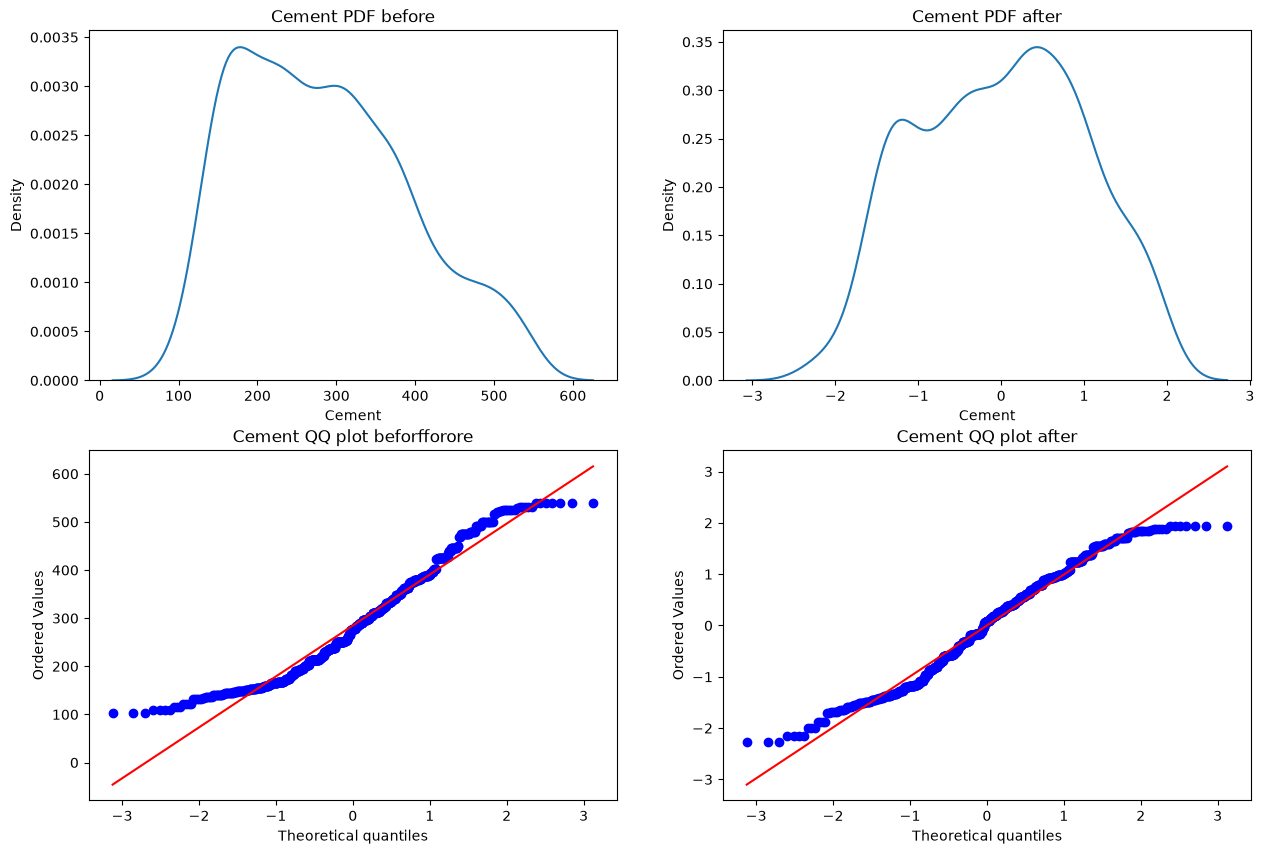

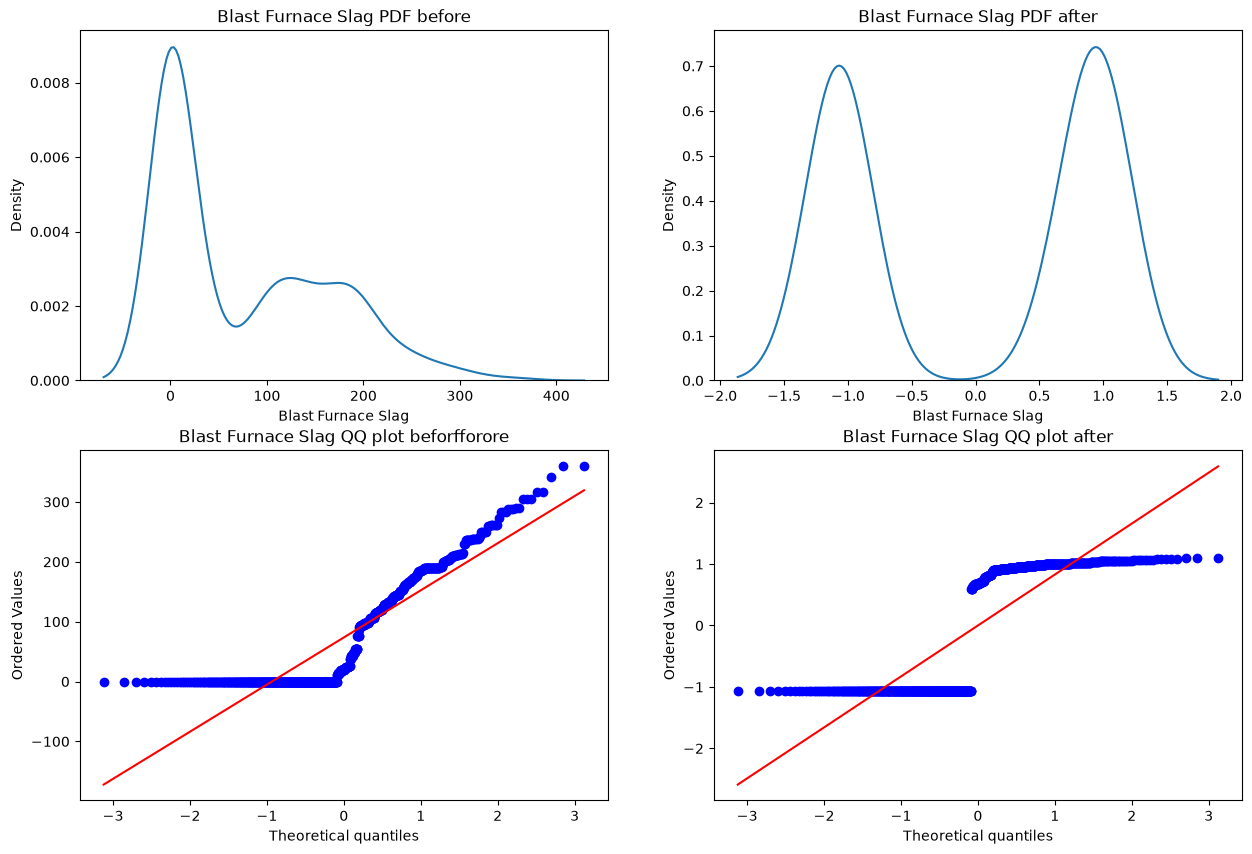

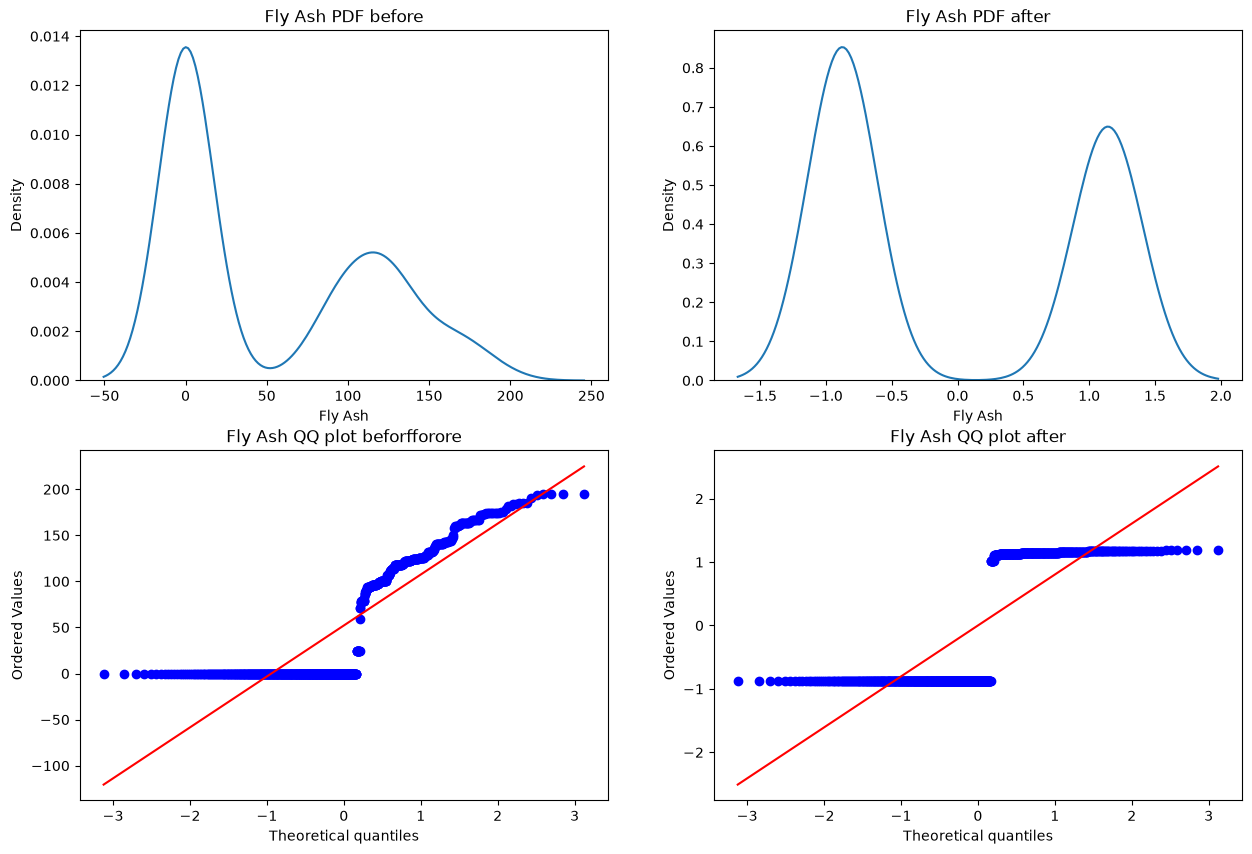

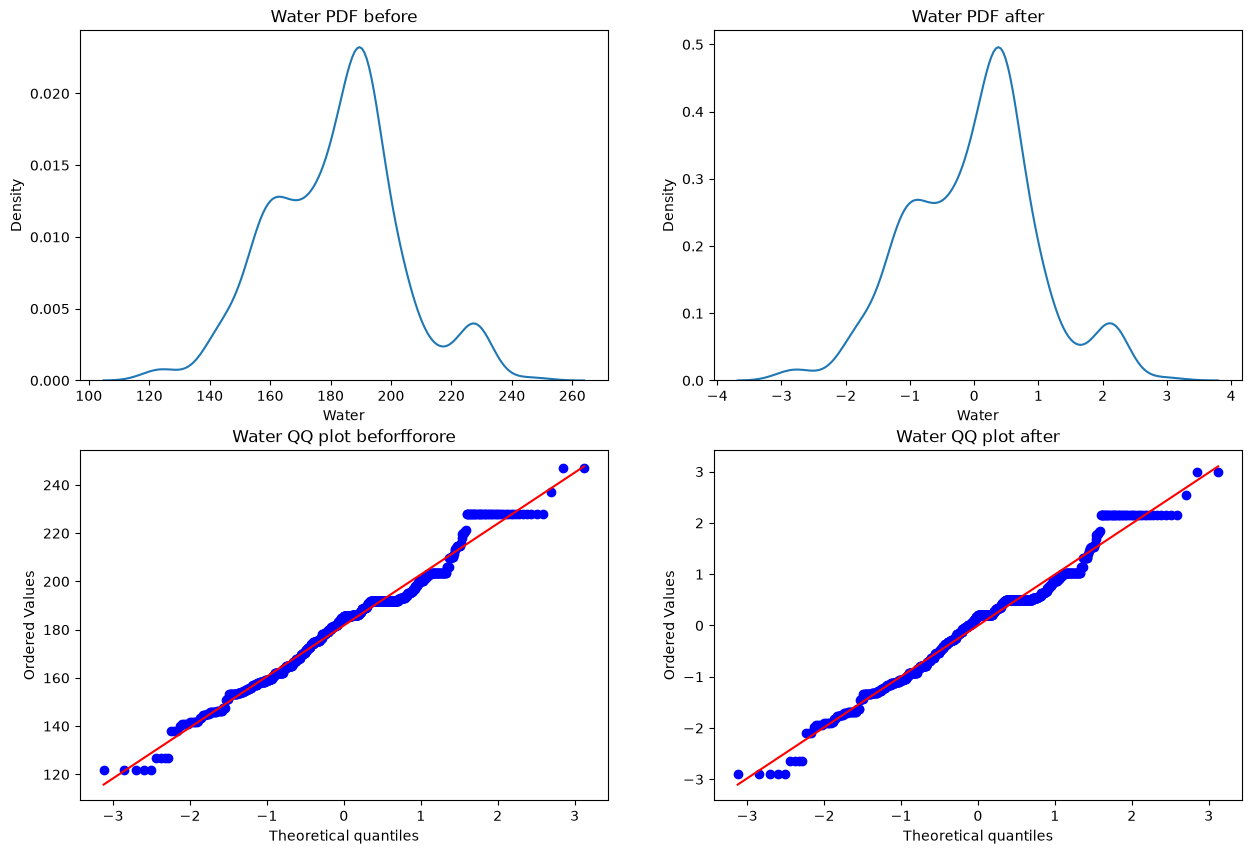

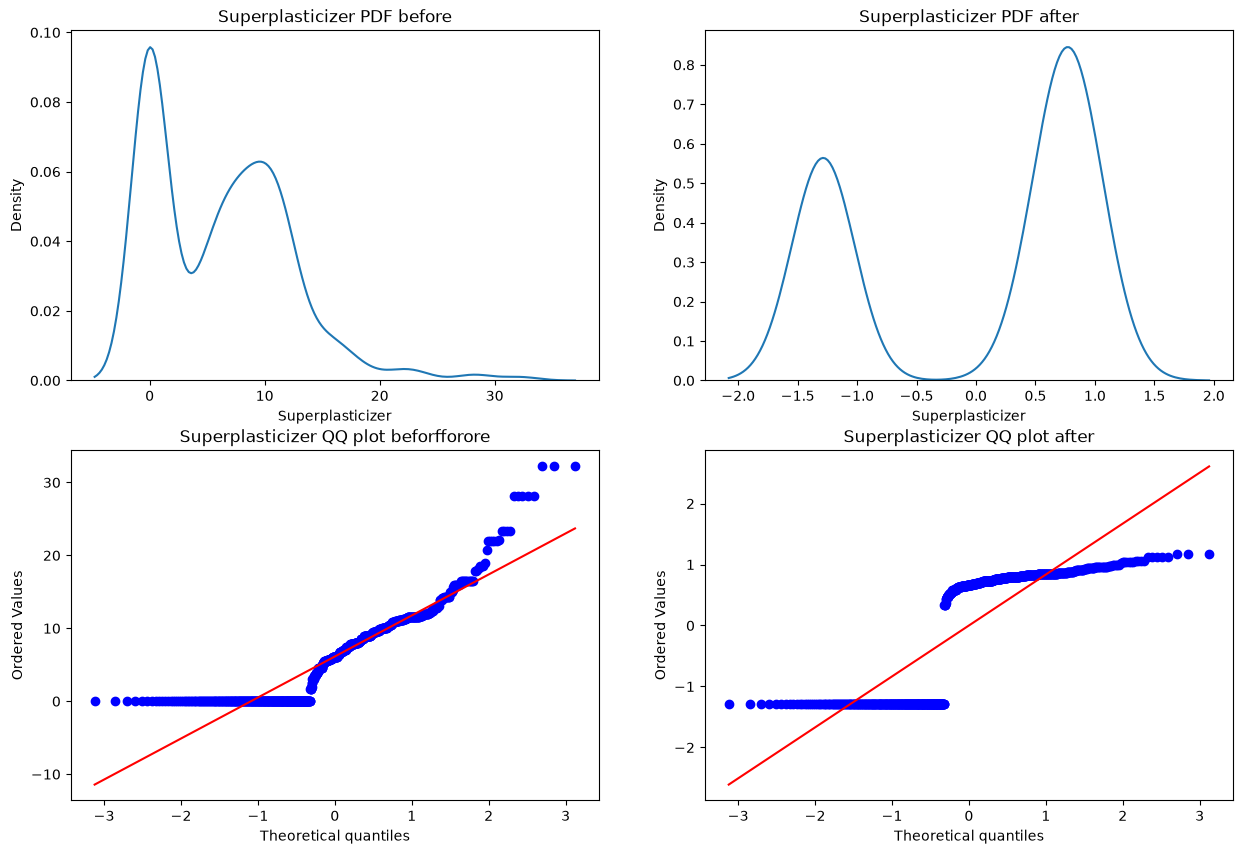

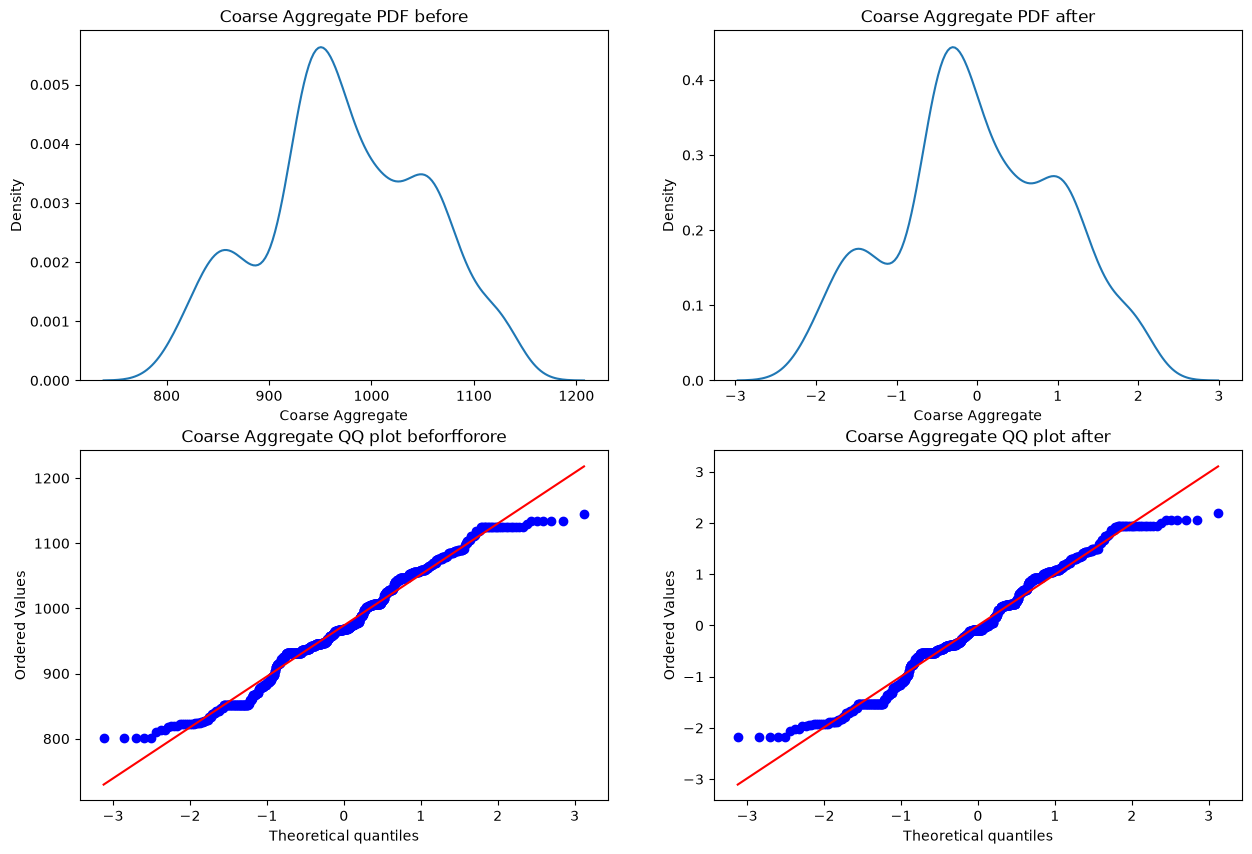

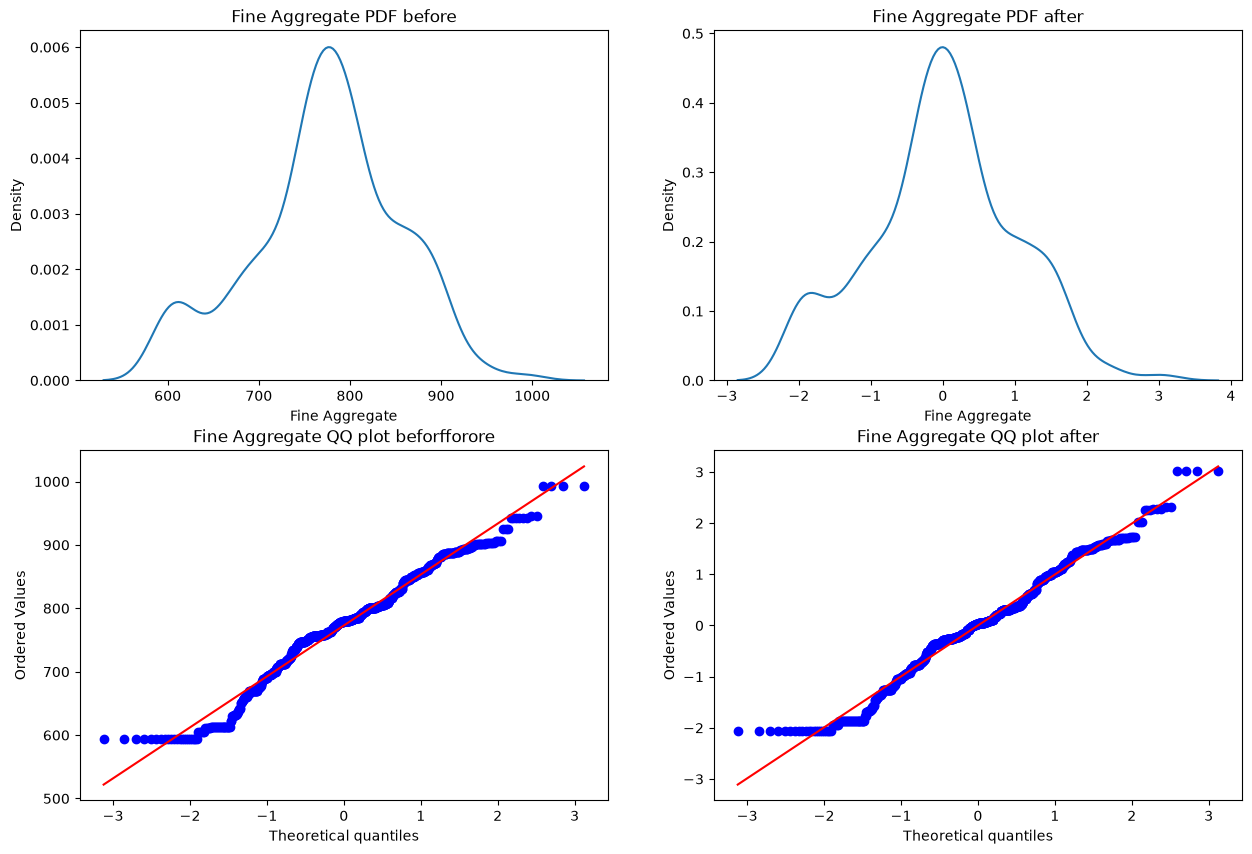

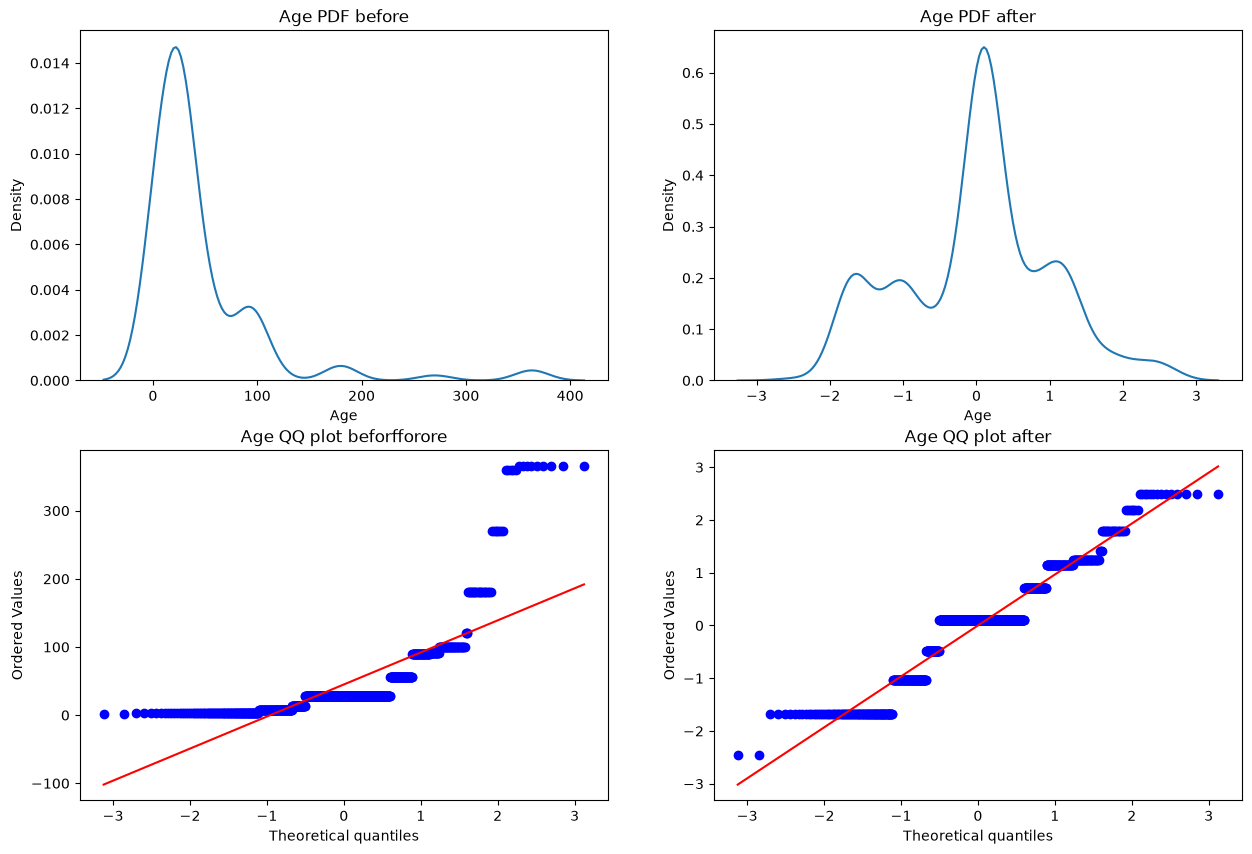

In [72]:
for column in X_train.columns:

    fig, ax = plt.subplots(2, 2, figsize = (15, 10))

    sns.kdeplot(X_train[column], ax= ax[0, 0])
    ax[0, 0].set_title(f'{column} PDF before')

    sns.kdeplot(X_train1[column], ax = ax[0, 1])
    ax[0, 1].set_title(f'{column} PDF after')

    sts.probplot(X_train[column], plot = ax[1, 0])
    ax[1, 0].set_title(f'{column} QQ plot beforfforore')

    sts.probplot(X_train1[column], plot = ax[1, 1])
    ax[1, 1].set_title(f'{column} QQ plot after')

In [73]:
cross_val_score(lr, X_train1, y_train, scoring= 'r2', cv= 5).mean()

np.float64(0.7931423306192557)

In [74]:
pt = PowerTransformer()

In [75]:
X_train2 = pt.fit_transform(X_train)
X_test2 = pt.transform(X_test)

In [90]:
df2 = pd.DataFrame({'cols' : X_train.columns, 'lambdas' : pt.lambdas_})
df2

,cols,lambdas
0,Cement,0.191971
1,Blast Furnace Slag,0.000482
2,Fly Ash,-0.178001
3,Water,0.850289
4,Superplasticizer,0.231695
5,Coarse Aggregate,1.126614
6,Fine Aggregate,1.860416
7,Age,0.019683


In [77]:
X_train2 = pd.DataFrame(X_train2, columns= X_train.columns)
X_test2 = pd.DataFrame(X_test2, columns = X_test.columns)

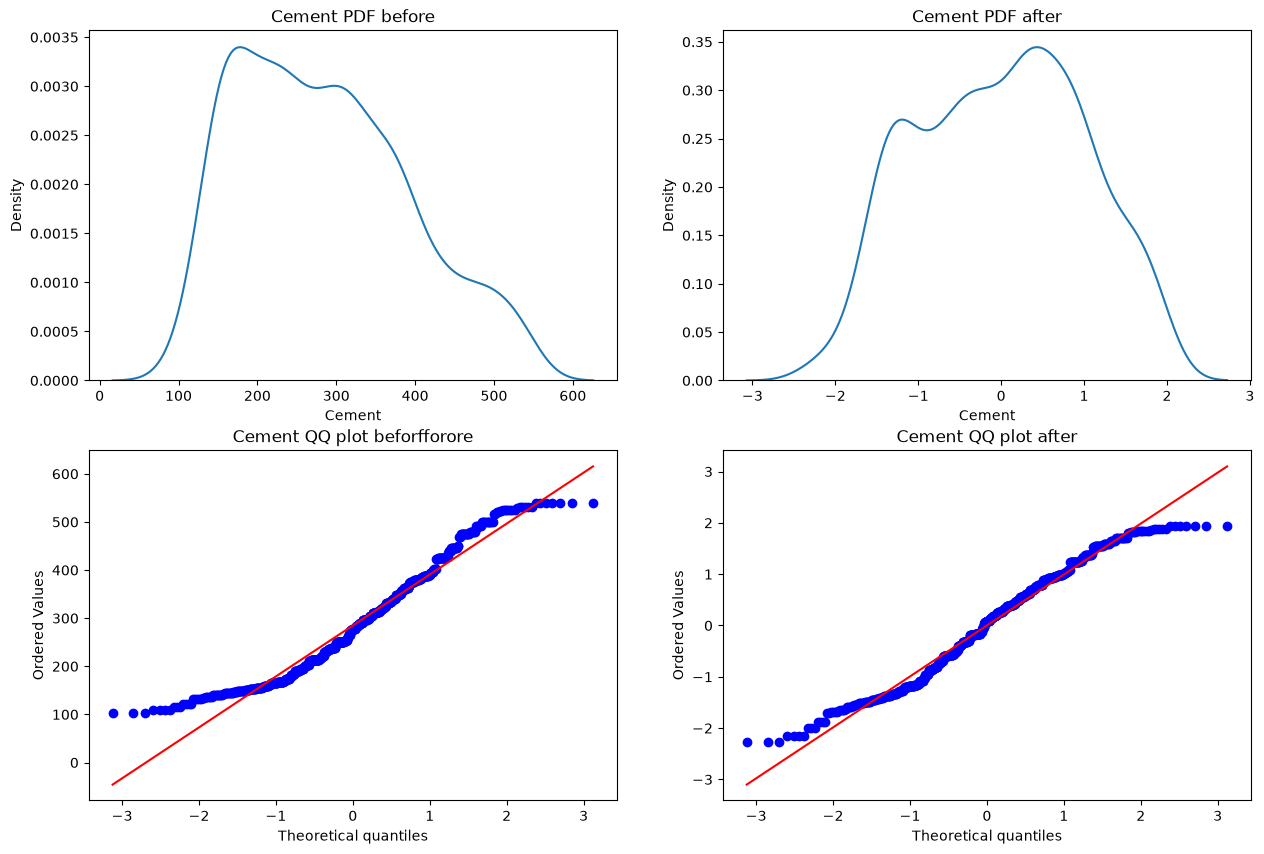

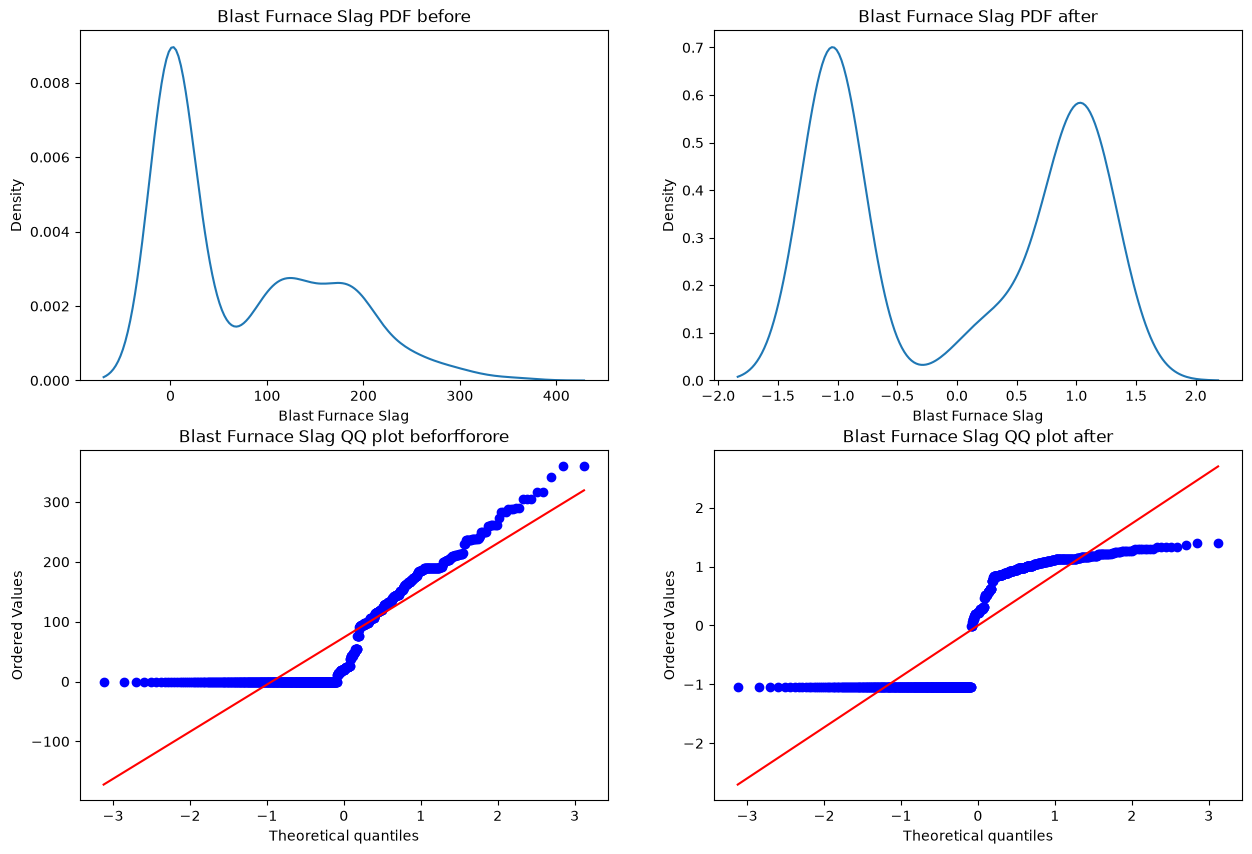

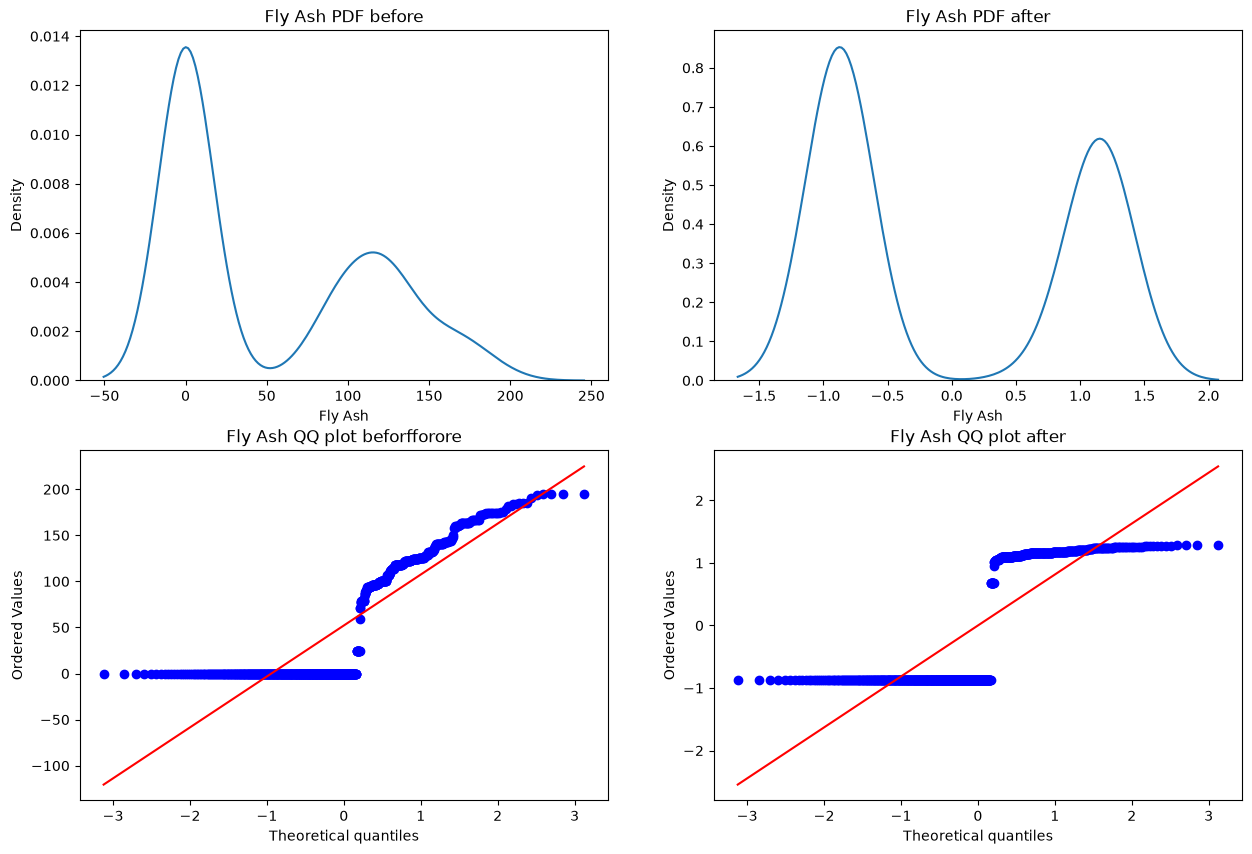

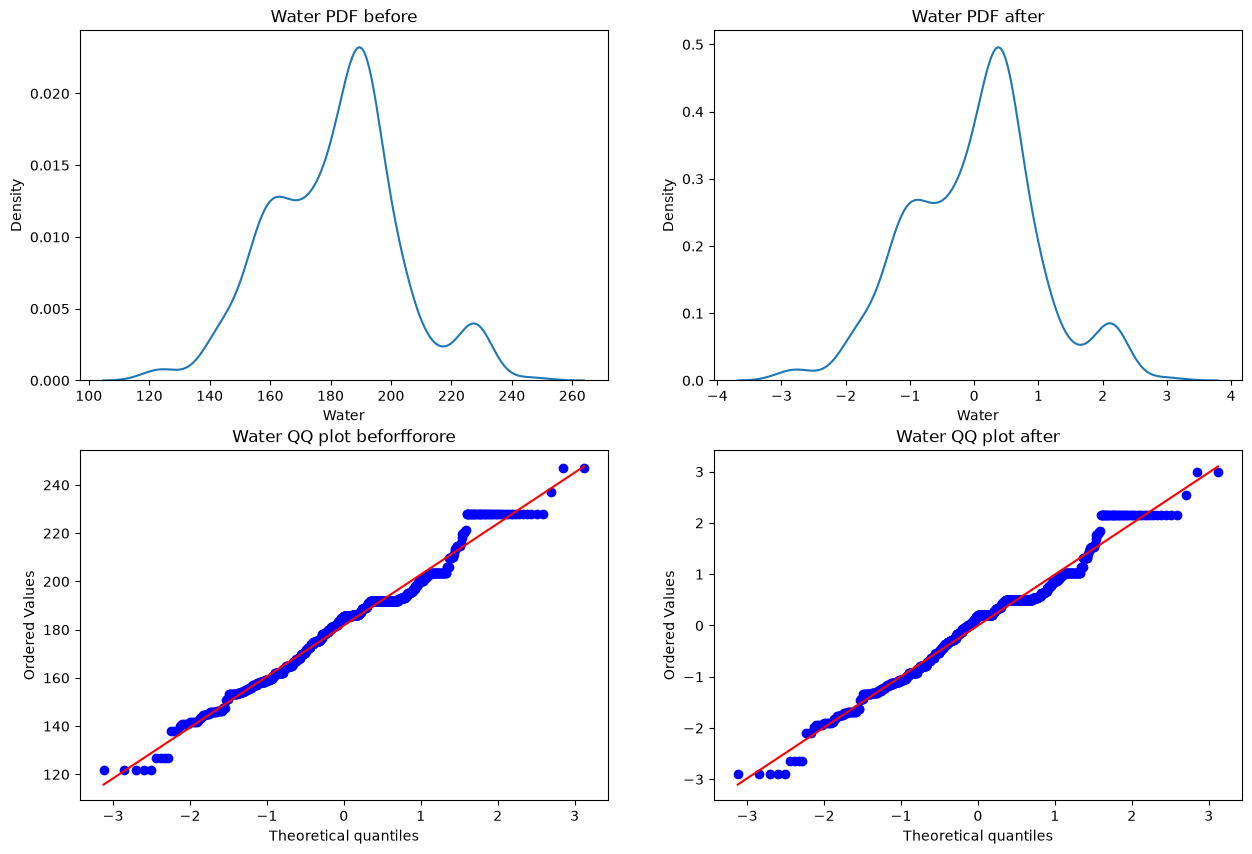

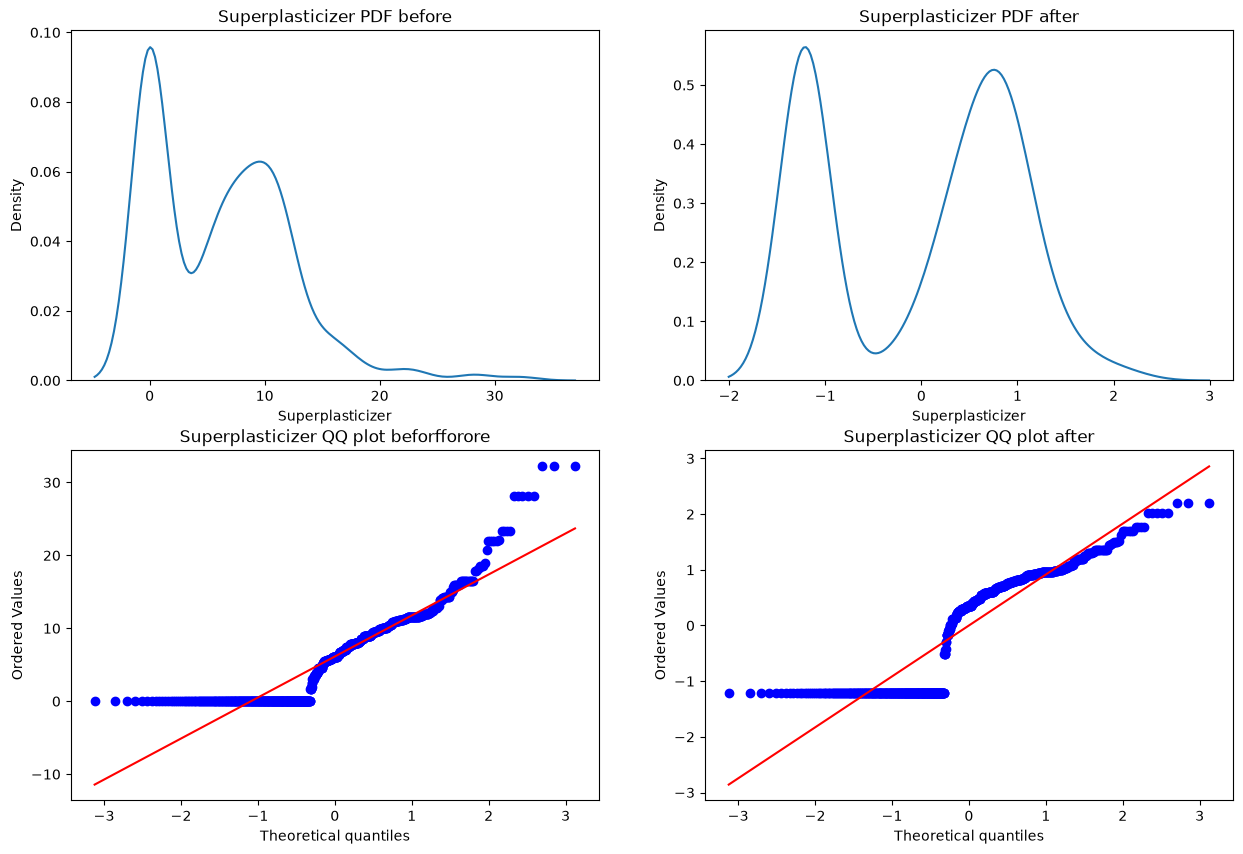

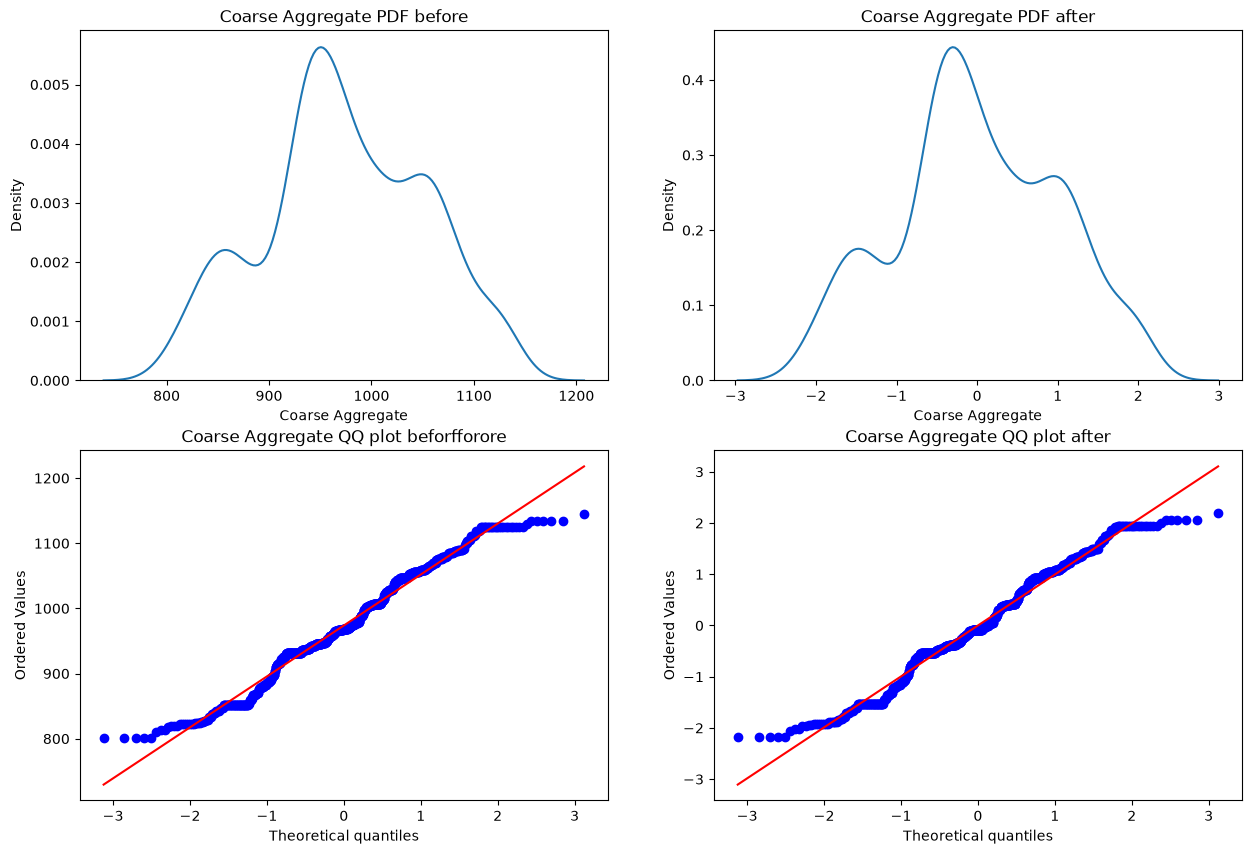

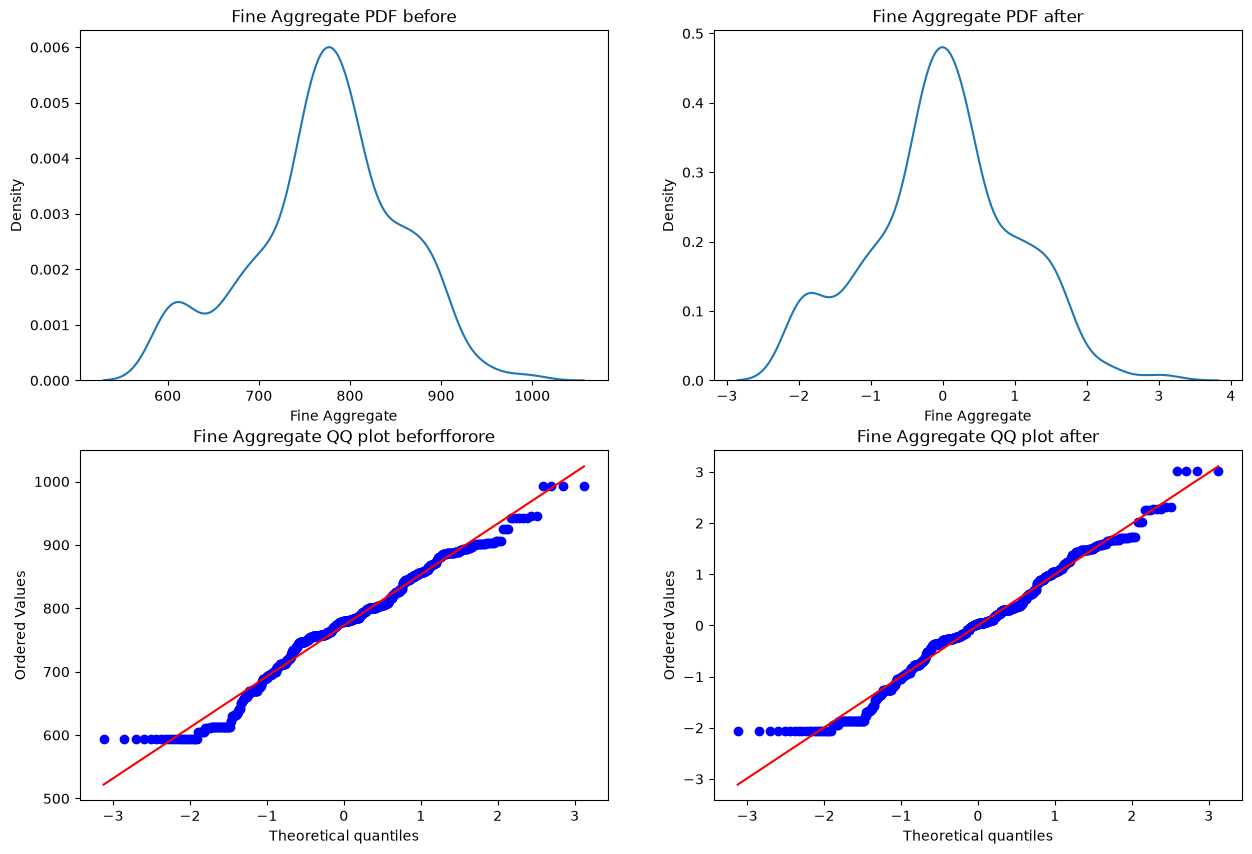

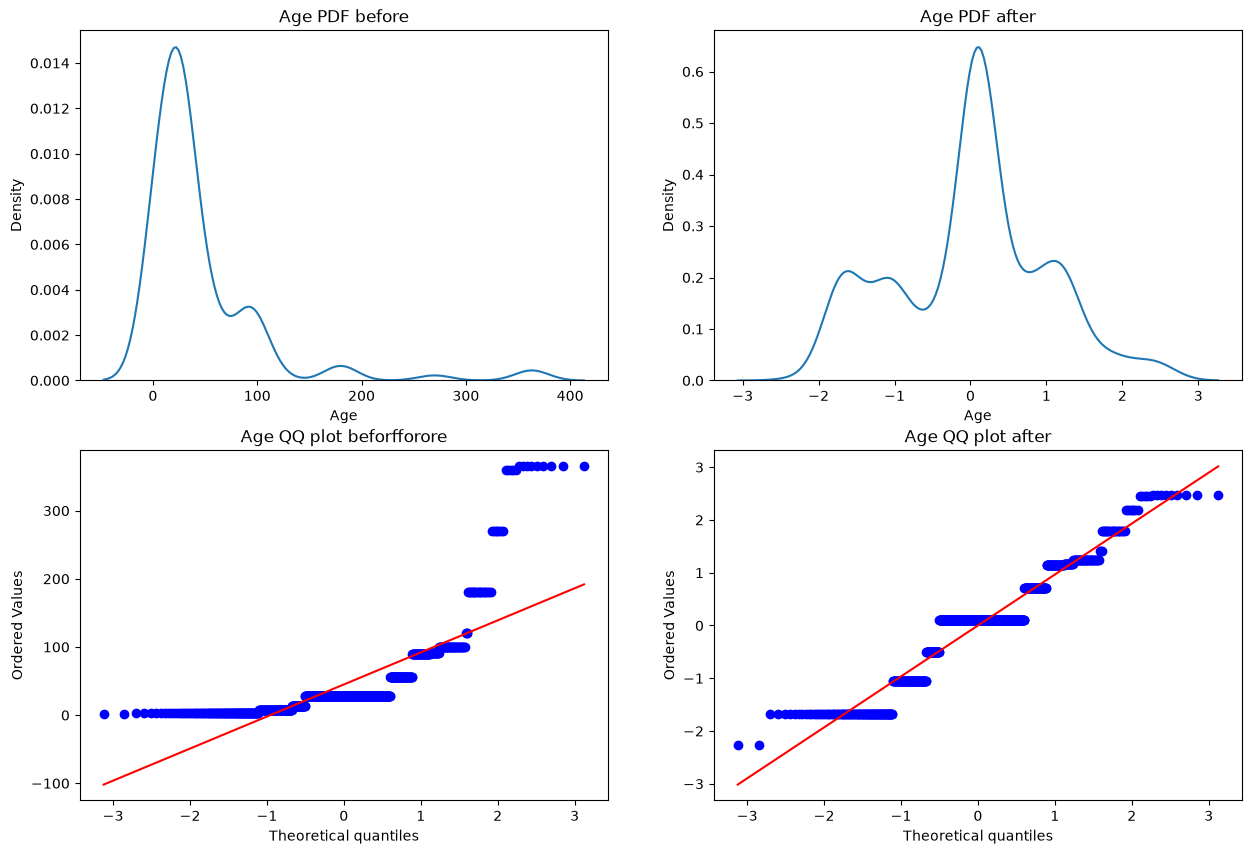

In [78]:
for column in X_train.columns:

    fig, ax = plt.subplots(2, 2, figsize = (15, 10))

    sns.kdeplot(X_train[column], ax= ax[0, 0])
    ax[0, 0].set_title(f'{column} PDF before')

    sns.kdeplot(X_train2[column], ax = ax[0, 1])
    ax[0, 1].set_title(f'{column} PDF after')

    sts.probplot(X_train[column], plot = ax[1, 0])
    ax[1, 0].set_title(f'{column} QQ plot beforfforore')

    sts.probplot(X_train2[column], plot = ax[1, 1])
    ax[1, 1].set_title(f'{column} QQ plot after')

In [79]:
cross_val_score(lr, X_train2, y_train, scoring= 'r2', cv= 5).mean()

np.float64(0.7949948320386907)

In [80]:
X_train.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
221,166.1,0.0,163.3,176.5,4.5,1058.6,780.1,28
235,213.8,98.1,24.5,181.7,6.7,1066.0,785.5,14
547,333.0,0.0,0.0,192.0,0.0,931.2,842.6,7
499,491.0,26.0,123.0,210.0,3.9,882.0,699.0,28
595,186.2,124.1,0.0,185.7,0.0,1083.4,764.3,28


In [81]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [82]:
tfs = ColumnTransformer([
                            ('power', PowerTransformer(), ['Blast Furnace Slag', 'Fly Ash', 'Superplasticizer']),
                            ('hue', PowerTransformer('box-cox'), ['Cement', 'Water', 'Coarse Aggregate', 'Fine Aggregate'])
                        ])

In [83]:
pipe = Pipeline([
                    ('trans', tfs),
                    ('model', lr)
                ])

In [84]:
cross_val_score(pipe, X_train, y_train, scoring= 'r2', cv= 5).mean()

np.float64(0.44703170677434034)

In [85]:
cross_val_score(lr, X_train, y_train, scoring= 'r2', cv= 5).mean()

np.float64(0.5913147611965391)

In [92]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('trans', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Cement','Blast Furnace Slag','Fly Ash',...,'Coarse Aggregate', 'Fine Aggregate','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('power', ...), ('hue', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset 

In [93]:
pipe.named_steps

{'trans': ColumnTransformer(transformers=[('power', PowerTransformer(),
                                  ['Blast Furnace Slag', 'Fly Ash',
                                   'Superplasticizer']),
                                 ('hue', PowerTransformer(method='box-cox'),
                                  ['Cement', 'Water', 'Coarse Aggregate',
                                   'Fine Aggregate'])]),
 'model': LinearRegression()}

In [99]:
pipe.named_steps.trans['power'].lambdas_

array([ 0.00048172, -0.17800052,  0.23169527])

In [100]:
pipe.named_steps.trans['hue'].lambdas_

array([0.19455895, 0.85123118, 1.12638407, 1.85922964])

In [104]:
pipe.named_steps['model'].intercept_

np.float64(35.89588082901554)